In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import sys
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = "/content/drive/MyDrive/simuteh"
NOTEBOOK_DIR = os.path.join(PROJECT_DIR, "notebook")
SRC_DIR = os.path.join(PROJECT_DIR, "src")
DATA_DIR = os.path.join(PROJECT_DIR, "data", "sintetis")
HASIL_DIR = os.path.join(PROJECT_DIR, "hasil")

os.chdir(NOTEBOOK_DIR)

if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)

from utils_cv import baca, tampil, kontras_bercak, statistik

print("Lingkungan B3 berhasil disiapkan.")
print("Folder proyek:", PROJECT_DIR)
print("Folder hasil:", HASIL_DIR)

Lingkungan B3 berhasil disiapkan.
Folder proyek: /content/drive/MyDrive/simuteh
Folder hasil: /content/drive/MyDrive/simuteh/hasil



teh_041.png
{'rerata': 183.4, 'simpangan_baku': 44.2, 'min': 64, 'maks': 237, 'persen_gelap': 0.0, 'persen_terang': 41.0}

teh_042.png
{'rerata': 126.6, 'simpangan_baku': 45.4, 'min': 15, 'maks': 178, 'persen_gelap': 15.2, 'persen_terang': 0.0}

teh_043.png
{'rerata': 213.0, 'simpangan_baku': 26.7, 'min': 132, 'maks': 255, 'persen_gelap': 0.0, 'persen_terang': 74.9}

teh_044.png
{'rerata': 158.5, 'simpangan_baku': 13.2, 'min': 113, 'maks': 186, 'persen_gelap': 0.0, 'persen_terang': 0.0}

teh_045.png
{'rerata': 127.8, 'simpangan_baku': 57.9, 'min': 28, 'maks': 248, 'persen_gelap': 1.8, 'persen_terang': 15.0}


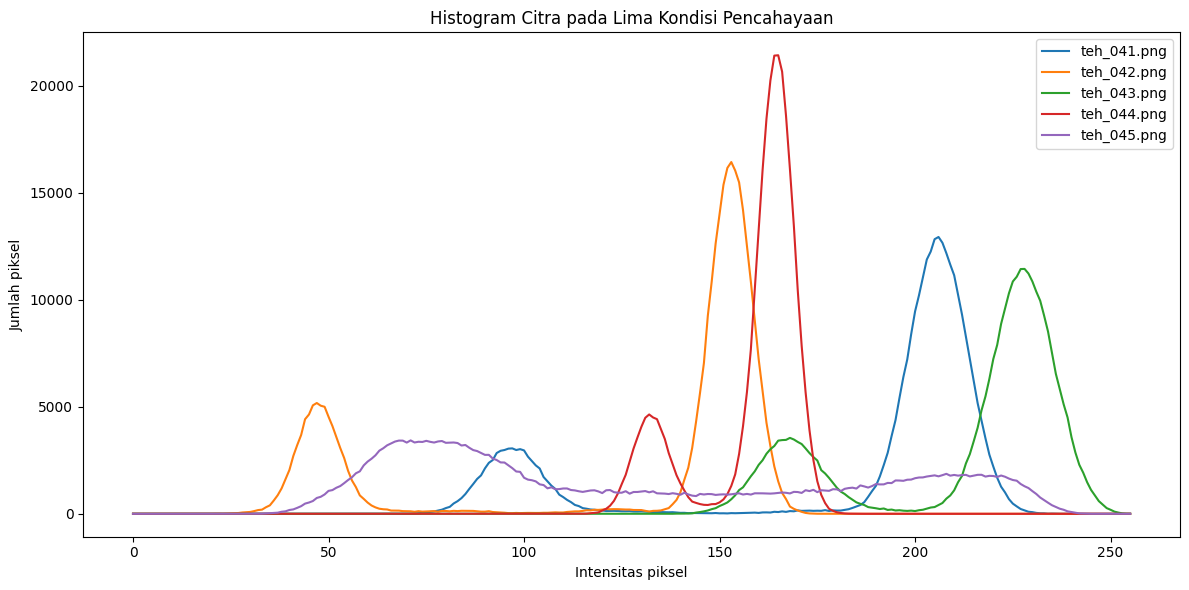

,nama_file,rerata,simpangan_baku,minimum,maksimum,persen_gelap,persen_terang
0,teh_041.png,183.449619,44.164209,64,237,0.000000,59.955404
1,teh_042.png,126.608864,45.356890,15,178,15.248047,0.000000
2,teh_043.png,212.986061,26.724870,132,255,0.000000,75.315104
3,teh_044.png,158.509707,13.163096,113,186,0.000000,0.000000
4,teh_045.png,127.812878,57.857860,28,248,1.764974,17.842122


In [3]:
nama_citra = [
    "teh_041.png",
    "teh_042.png",
    "teh_043.png",
    "teh_044.png",
    "teh_045.png"
]

hasil_statistik = []

plt.figure(figsize=(12, 6))

for nama in nama_citra:
    path = os.path.join(DATA_DIR, "citra", nama)

    img = baca(path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    stat = statistik(gray)

    print(f"\n{nama}")
    print(stat)

    hasil_statistik.append({
        "nama_file": nama,
        "rerata": float(np.mean(gray)),
        "simpangan_baku": float(np.std(gray)),
        "minimum": int(np.min(gray)),
        "maksimum": int(np.max(gray)),
        "persen_gelap": float(np.mean(gray < 50) * 100),
        "persen_terang": float(np.mean(gray > 200) * 100)
    })

    hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
    plt.plot(hist, label=nama)

plt.xlabel("Intensitas piksel")
plt.ylabel("Jumlah piksel")
plt.title("Histogram Citra pada Lima Kondisi Pencahayaan")
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(HASIL_DIR, "b3_histogram_5kondisi.png"),
    dpi=150,
    bbox_inches="tight"
)

plt.show()

tabel_statistik = pd.DataFrame(hasil_statistik)
display(tabel_statistik)

In [4]:
tabel_statistik.to_csv(
    os.path.join(HASIL_DIR, "b3_tabel9_diagnosis.csv"),
    index=False
)

print("Tabel statistik B3 berhasil disimpan.")

Tabel statistik B3 berhasil disimpan.



teh_021.png
{'rerata': 168.7, 'simpangan_baku': 42.3, 'min': 64, 'maks': 228, 'persen_gelap': 0.0, 'persen_terang': 4.2}

teh_022.png
{'rerata': 117.4, 'simpangan_baku': 39.5, 'min': 23, 'maks': 166, 'persen_gelap': 15.6, 'persen_terang': 0.0}

teh_023.png
{'rerata': 215.0, 'simpangan_baku': 28.4, 'min': 142, 'maks': 251, 'persen_gelap': 0.0, 'persen_terang': 73.4}

teh_024.png
{'rerata': 153.7, 'simpangan_baku': 13.8, 'min': 103, 'maks': 191, 'persen_gelap': 0.0, 'persen_terang': 0.0}

teh_025.png
{'rerata': 124.0, 'simpangan_baku': 55.6, 'min': 28, 'maks': 239, 'persen_gelap': 1.6, 'persen_terang': 10.2}


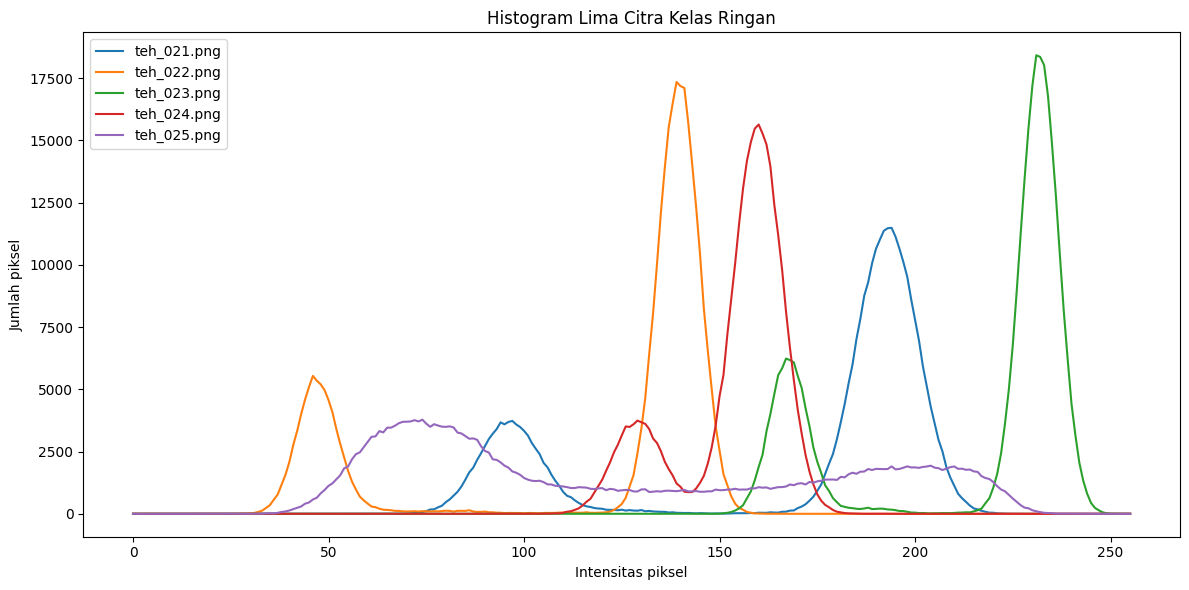

,nama_file,rerata,simpangan_baku,minimum,maksimum,persen_gelap,persen_terang
0,teh_021.png,168.663089,42.328295,64,228,0.000000,12.654948
1,teh_022.png,117.364007,39.491554,23,166,15.593424,0.000000
2,teh_023.png,215.005413,28.392291,142,251,0.000000,73.469401
3,teh_024.png,153.718750,13.770297,103,191,0.000000,0.000000
4,teh_025.png,124.018757,55.558652,28,239,1.626628,13.299154


Statistik kelas ringan berhasil disimpan.


In [5]:
nama_ringan = [
    "teh_021.png",
    "teh_022.png",
    "teh_023.png",
    "teh_024.png",
    "teh_025.png"
]

hasil_ringan = []

plt.figure(figsize=(12, 6))

for nama in nama_ringan:
    path = os.path.join(DATA_DIR, "citra", nama)

    img = baca(path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    stat = statistik(gray)

    print(f"\n{nama}")
    print(stat)

    hasil_ringan.append({
        "nama_file": nama,
        "rerata": float(np.mean(gray)),
        "simpangan_baku": float(np.std(gray)),
        "minimum": int(np.min(gray)),
        "maksimum": int(np.max(gray)),
        "persen_gelap": float(np.mean(gray < 50) * 100),
        "persen_terang": float(np.mean(gray > 200) * 100)
    })

    hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
    plt.plot(hist, label=nama)

plt.xlabel("Intensitas piksel")
plt.ylabel("Jumlah piksel")
plt.title("Histogram Lima Citra Kelas Ringan")
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(HASIL_DIR, "b3_histogram_5citra_ringan.png"),
    dpi=150,
    bbox_inches="tight"
)

plt.show()

tabel_ringan = pd.DataFrame(hasil_ringan)

tabel_ringan.to_csv(
    os.path.join(HASIL_DIR, "b3_statistik_ringan.csv"),
    index=False
)

display(tabel_ringan)

print("Statistik kelas ringan berhasil disimpan.")

In [6]:
# B3 Langkah 3.3: Perbaikan citra teh_045.png

nama = "teh_045.png"

# Baca citra dan mask
img = baca(os.path.join(DATA_DIR, "citra", nama))
md = cv2.imread(os.path.join(DATA_DIR, "mask_daun", nama), 0)
mb = cv2.imread(os.path.join(DATA_DIR, "mask_bercak", nama), 0)

# Ubah citra ke grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Fungsi gamma correction
def gamma_lut(g):
    lut = np.array([255 * (i / 255) ** g for i in range(256)])
    return np.clip(lut, 0, 255).astype(np.uint8)

# Regangan kontras berdasarkan persentil 2 dan 98
rmin, rmax = np.percentile(gray, (2, 98))

# Terapkan metode perbaikan citra
hasil_perbaikan = {
    "asli": gray,
    "negatif": 255 - gray,
    "cerah+50": cv2.convertScaleAbs(gray, alpha=1.0, beta=50),
    "kontras": cv2.convertScaleAbs(gray, alpha=1.5, beta=-40),
    "regang": np.clip(
        (gray.astype(np.float32) - rmin) / (rmax - rmin) * 255,
        0, 255
    ).astype(np.uint8),
    "gamma0.5": cv2.LUT(gray, gamma_lut(0.5)),
    "gamma1.8": cv2.LUT(gray, gamma_lut(1.8)),
    "ekualisasi": cv2.equalizeHist(gray),
    "CLAHE": cv2.createCLAHE(
        clipLimit=2.0, tileGridSize=(8, 8)
    ).apply(gray)
}

# Hitung KB dan simpangan baku
hasil_tabel = []

for metode, citra_hasil in hasil_perbaikan.items():
    kb = kontras_bercak(citra_hasil, md, mb)
    simpangan_baku = float(np.std(citra_hasil))

    hasil_tabel.append({
        "metode": metode,
        "parameter": {
            "asli": "Tanpa perubahan",
            "negatif": "255 - intensitas",
            "cerah+50": "alpha=1.0, beta=50",
            "kontras": "alpha=1.5, beta=-40",
            "regang": "Persentil 2-98",
            "gamma0.5": "Gamma=0.5",
            "gamma1.8": "Gamma=1.8",
            "ekualisasi": "Histogram equalization",
            "CLAHE": "clipLimit=2.0, tileGridSize=(8,8)"
        }[metode],
        "KB": float(kb),
        "simpangan_baku": simpangan_baku
    })

tabel_perbaikan = pd.DataFrame(hasil_tabel)

# Simpan tabel hasil
path_csv = os.path.join(HASIL_DIR, "b3_tabel10_perbaikan.csv")
tabel_perbaikan.to_csv(path_csv, index=False)

display(tabel_perbaikan)
print("Tabel hasil disimpan:", path_csv)

,metode,parameter,KB,simpangan_baku
0,asli,Tanpa perubahan,1.613110,57.857860
1,negatif,255 - intensitas,1.613110,57.857860
2,cerah+50,"alpha=1.0, beta=50",1.613110,54.625830
3,kontras,"alpha=1.5, beta=-40",1.612794,78.825644
4,regang,Persentil 2-98,1.658951,82.081141
5,gamma0.5,Gamma=0.5,1.428610,40.891695
6,gamma1.8,Gamma=1.8,1.938716,64.061292
7,ekualisasi,Histogram equalization,1.224103,73.426227
8,CLAHE,"clipLimit=2.0, tileGridSize=(8,8)",2.089196,48.827094


Tabel hasil disimpan: /content/drive/MyDrive/simuteh/hasil/b3_tabel10_perbaikan.csv


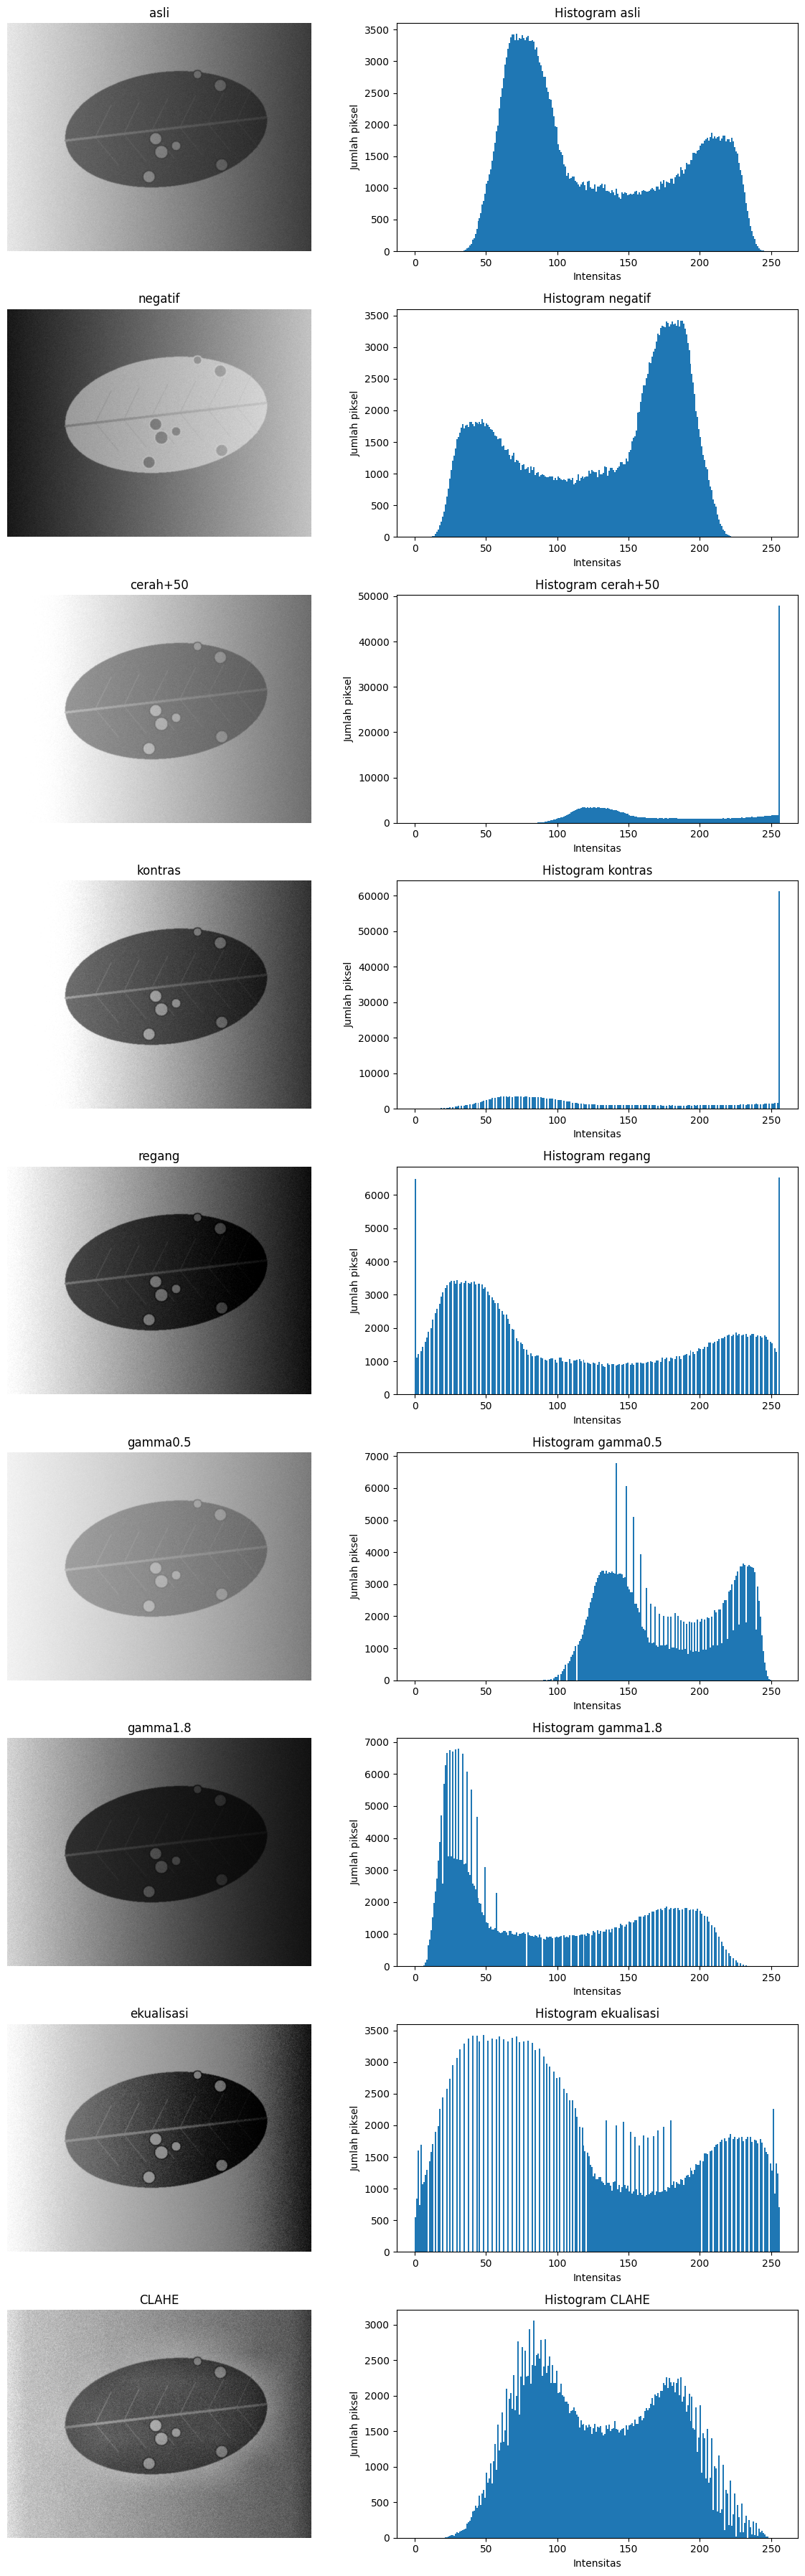

Gambar hasil disimpan: /content/drive/MyDrive/simuteh/hasil/b3_perbaikan_teh_045.png


In [7]:
# Tampilkan setiap hasil perbaikan beserta histogramnya

fig, axes = plt.subplots(
    len(hasil_perbaikan), 2,
    figsize=(12, 4 * len(hasil_perbaikan))
)

for i, (metode, citra_hasil) in enumerate(hasil_perbaikan.items()):
    axes[i, 0].imshow(citra_hasil, cmap="gray", vmin=0, vmax=255)
    axes[i, 0].set_title(metode)
    axes[i, 0].axis("off")

    axes[i, 1].hist(
        citra_hasil.ravel(),
        bins=256,
        range=(0, 256)
    )
    axes[i, 1].set_title(f"Histogram {metode}")
    axes[i, 1].set_xlabel("Intensitas")
    axes[i, 1].set_ylabel("Jumlah piksel")

plt.tight_layout()

path_gambar = os.path.join(HASIL_DIR, "b3_perbaikan_teh_045.png")
plt.savefig(path_gambar, dpi=150, bbox_inches="tight")
plt.show()

print("Gambar hasil disimpan:", path_gambar)

In [9]:
# B3 Langkah 3.4: Eksperimen parameter CLAHE

hasil_clahe = []

# Uji kombinasi clipLimit dan tileGridSize
for clip in [1.0, 2.0, 4.0]:
    for tile in [4, 8, 16]:
        clahe = cv2.createCLAHE(
            clipLimit=clip,
            tileGridSize=(tile, tile)
        )

        citra_hasil = clahe.apply(gray)
        kb = kontras_bercak(citra_hasil, md, mb)
        std = float(np.std(citra_hasil))

        hasil_clahe.append({
            "clipLimit": clip,
            "tileGridSize": f"{tile}x{tile}",
            "KB": float(kb),
            "simpangan_baku": std
        })

tabel_clahe = pd.DataFrame(hasil_clahe)

# Simpan tabel hasil eksperimen
path_clahe = os.path.join(HASIL_DIR, "b3_clahe_parameter.csv")
tabel_clahe.to_csv(path_clahe, index=False)

display(tabel_clahe)
print("Tabel eksperimen CLAHE disimpan:", path_clahe)

,clipLimit,tileGridSize,KB,simpangan_baku
0,1.0,4x4,2.452025,52.941905
1,1.0,8x8,2.176549,52.813350
2,1.0,16x16,2.288209,53.301148
3,2.0,4x4,2.448239,49.402763
4,2.0,8x8,2.089196,48.827094
5,2.0,16x16,2.083913,50.449581
6,4.0,4x4,2.173529,47.910805
7,4.0,8x8,1.812263,44.766417
8,4.0,16x16,1.846971,46.000713


Tabel eksperimen CLAHE disimpan: /content/drive/MyDrive/simuteh/hasil/b3_clahe_parameter.csv


Gambar perbandingan disimpan: /content/drive/MyDrive/simuteh/hasil/b3_clahe_warna.png


,metode,KB
0,Citra asli,1.613110
1,CLAHE kanal V HSV,2.335650
2,CLAHE tiap kanal BGR,2.289437


Tabel perbandingan disimpan: /content/drive/MyDrive/simuteh/hasil/b3_perbandingan_clahe_warna.csv


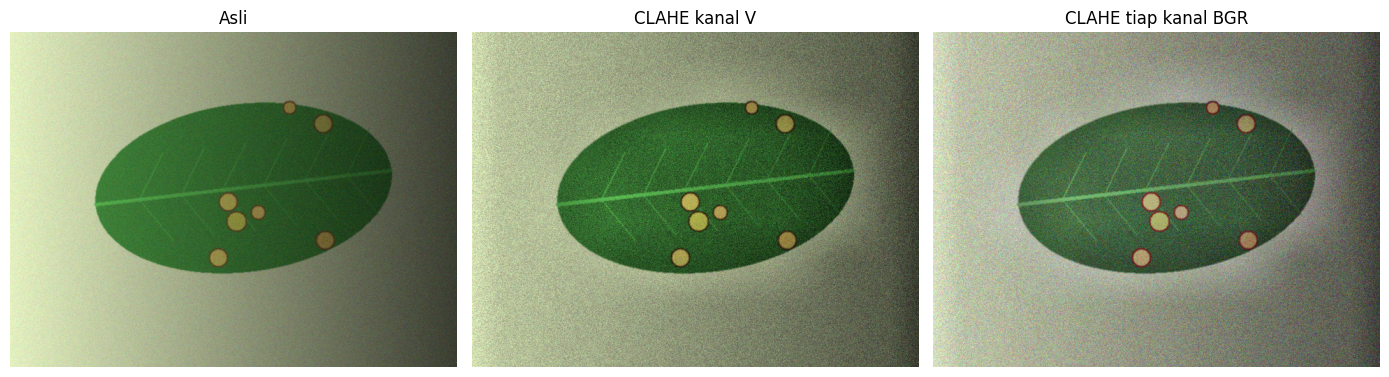

In [11]:
# Perbandingan CLAHE kanal V HSV dan setiap kanal BGR

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

# Metode 1: CLAHE pada kanal V HSV
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
via_v = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

# Metode 2: CLAHE pada setiap kanal BGR
kanal_bgr = cv2.split(img)
via_bgr = cv2.merge([
    clahe.apply(kanal) for kanal in kanal_bgr
])

# Tampilkan hasil perbandingan
tampil(
    [img, via_v, via_bgr],
    ["Asli", "CLAHE kanal V", "CLAHE tiap kanal BGR"]
)

# Simpan gambar perbandingan
path_perbandingan = os.path.join(
    HASIL_DIR, "b3_clahe_warna.png"
)

panel = np.hstack([img, via_v, via_bgr])
cv2.imwrite(path_perbandingan, panel)

print("Gambar perbandingan disimpan:", path_perbandingan)

# Hitung KB masing-masing hasil
gray_v = cv2.cvtColor(via_v, cv2.COLOR_BGR2GRAY)
gray_bgr = cv2.cvtColor(via_bgr, cv2.COLOR_BGR2GRAY)

hasil_perbandingan = pd.DataFrame([
    {
        "metode": "Citra asli",
        "KB": float(kontras_bercak(gray, md, mb))
    },
    {
        "metode": "CLAHE kanal V HSV",
        "KB": float(kontras_bercak(gray_v, md, mb))
    },
    {
        "metode": "CLAHE tiap kanal BGR",
        "KB": float(kontras_bercak(gray_bgr, md, mb))
    }
])

path_perbandingan_csv = os.path.join(
    HASIL_DIR, "b3_perbandingan_clahe_warna.csv"
)

hasil_perbandingan.to_csv(path_perbandingan_csv, index=False)

display(hasil_perbandingan)
print("Tabel perbandingan disimpan:", path_perbandingan_csv)
